# Redaction benchmark

Reads the redaction evaluation report, shows the results as tables, and draws PNG charts. Edit the **Settings** cell and run all cells.
Synthetic data only: this is not a guarantee for real applications.

In [1]:
%pip install matplotlib


Note: you may need to restart the kernel to use updated packages.


In [2]:
# ---- Settings: change these ----
REPORT = "redaction_benchmark.md"   # report to read (relative to this notebook)
RERUN = False                       # True: run `python -m redaction.eval` first (needs the project's environment, ~10 s)
TITLE = "Redaction accuracy on the synthetic evaluation set"
BAR_COLOR = "#1b5e8a"
WARN_COLOR = "#c0392b"              # bars below the threshold
THRESHOLD = 100                     # recall (%) below this is drawn in WARN_COLOR
SHOW_TYPES = None                   # e.g. ["PERSON", "EMAIL"] to show only these types; None = all
SHOW_CULTURES = None                # e.g. ["Vietnamese (family first)"]; None = all
OUT_DIR = "."                       # where the PNGs are saved

In [3]:
import re, subprocess, sys
from pathlib import Path
import matplotlib.pyplot as plt

here = Path.cwd()
report = (here / REPORT).resolve()
if RERUN:
    root = report.parent.parent
    subprocess.run([sys.executable, "-m", "redaction.eval", "--out", str(report)], cwd=root, check=True)
text = report.read_text(encoding="utf-8")
print("Report:", report.name, "|", re.search(r"Generated (.+?) in", text).group(1))

Report: redaction_benchmark.md | 2026-10-13 08:54 UTC


## Parse the report

In [4]:
def section_rows(heading):
    """Table rows (list of cells) under the first '## heading'."""
    body = text.split(f"## {heading}", 1)[1].split("\n## ", 1)[0]
    rows = [[c.strip() for c in l.strip().strip("|").split("|")] for l in body.splitlines() if l.startswith("|")]
    return rows[2:]  # drop header and separator

def frac(s):
    m = re.match(r"(\d+)/(\d+)", s)
    return (int(m[1]), int(m[2])) if m else (0, 0)

summary = {k.replace("**", ""): v.replace("**", "") for k, v in section_rows("Summary")}
by_type = [dict(type=r[0], present=int(r[1]), removed=int(r[2]), leaked=int(r[3]), reached=int(r[4]), recall=int(r[5].rstrip("%")))
           for r in section_rows("Results by entity type")]
cultures = [dict(group=r[0], det=frac(r[1]), missed=int(r[3]), known=frac(r[4])) for r in section_rows("Name recall by culture")
            if re.match(r"\d+/\d+", r[1])]
if SHOW_TYPES: by_type = [t for t in by_type if t["type"] in SHOW_TYPES]
if SHOW_CULTURES: cultures = [c for c in cultures if c["group"] in SHOW_CULTURES]

## Summary table

In [5]:
try:
    import pandas as pd
    from IPython.display import display
    display(pd.DataFrame(summary.items(), columns=["Measure", "Result"]))
    display(pd.DataFrame(by_type))
    display(pd.DataFrame([dict(group=c["group"], detector=f"{c['det'][0]}/{c['det'][1]}", missed=c["missed"],
                               known=f"{c['known'][0]}/{c['known'][1]}") for c in cultures]))
except ImportError:   # no pandas: plain text
    for k, v in summary.items(): print(f"{k:<75} {v}")
    for t in by_type: print(t)
    for c in cultures: print(c)

Labelled personal values (present in the input)                             95
Recall (values fully removed from the redacted text)                        95/95 (100.0%)
Values left in the redacted text (any part)                                 0
...of which would actually reach the LLM (leak scan did not block)          0
Over-redaction (needed terms wrongly removed)                               0/128 (0.0%)
Unexpected redactions (probable over-redaction, listed below)               8
Cases blocked by the leak scan (no LLM call)                                0/24
{'type': 'ADDRESS', 'present': 10, 'removed': 10, 'leaked': 0, 'reached': 0, 'recall': 100}
{'type': 'DOB', 'present': 10, 'removed': 10, 'leaked': 0, 'reached': 0, 'recall': 100}
{'type': 'EMAIL', 'present': 12, 'removed': 12, 'leaked': 0, 'reached': 0, 'recall': 100}
{'type': 'HANDLE', 'present': 1, 'removed': 1, 'leaked': 0, 'reached': 0, 'recall': 100}
{'type': 'ID', 'present': 2, 'removed': 2, 'leaked': 0, 'reached': 

## Chart: headline numbers and recall by type

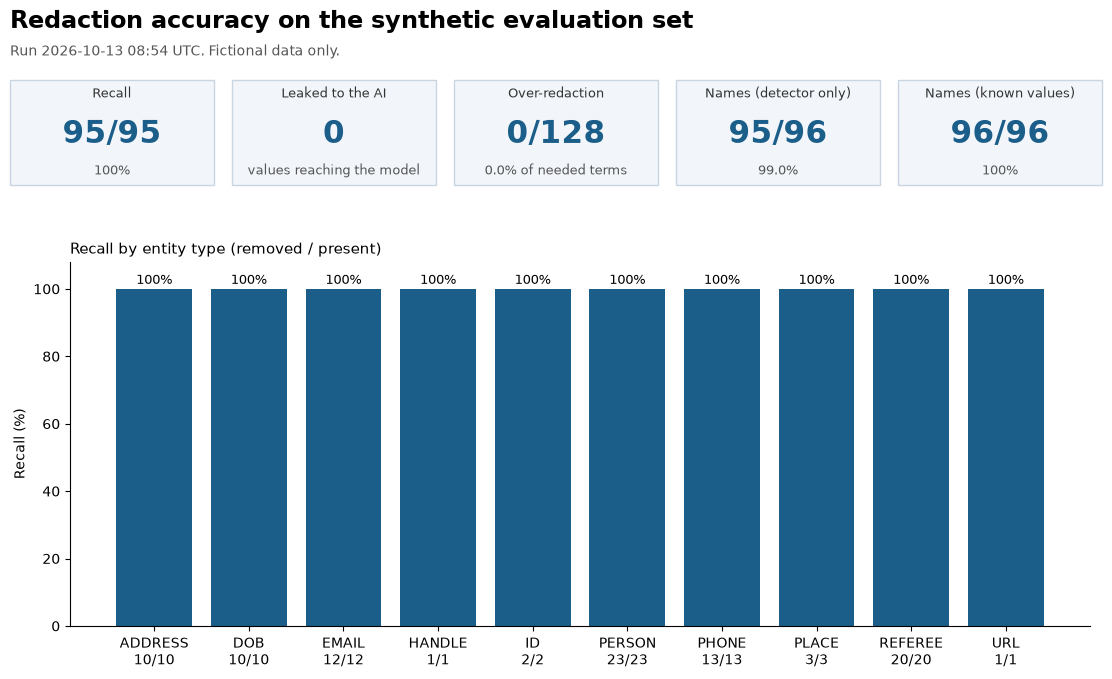

In [6]:
fig = plt.figure(figsize=(12, 7), facecolor="white")
fig.suptitle(TITLE, fontsize=17, fontweight="bold", x=0.05, ha="left")
fig.text(0.05, 0.915, "Run " + re.search(r"Generated (.+?) UTC", text).group(1) + " UTC. Fictional data only.", fontsize=10, color="#555")
det_ok, det_all = (sum(c["det"][i] for c in cultures) for i in (0, 1))
kn_ok, kn_all = (sum(c["known"][i] for c in cultures) for i in (0, 1))
rec = frac(next(v for k, v in summary.items() if k.startswith("Recall")))
over = frac(next(v for k, v in summary.items() if k.startswith("Over-redaction")))
tiles = [("Recall", f"{rec[0]}/{rec[1]}", f"{rec[0]/max(rec[1],1):.0%}"),
         ("Leaked to the AI", str(sum(t["reached"] for t in by_type)), "values reaching the model"),
         ("Over-redaction", f"{over[0]}/{over[1]}", f"{over[0]/max(over[1],1):.1%} of needed terms"),
         ("Names (detector only)", f"{det_ok}/{det_all}", f"{det_ok/max(det_all,1):.1%}"),
         ("Names (known values)", f"{kn_ok}/{kn_all}", f"{kn_ok/max(kn_all,1):.0%}")]
for i, (a, b, c) in enumerate(tiles):
    x = 0.05 + i * 0.185
    fig.patches.append(plt.Rectangle((x, 0.73), 0.17, 0.15, transform=fig.transFigure, fc="#f2f6fa", ec="#c9d6e2"))
    fig.text(x + 0.085, 0.855, a, ha="center", fontsize=9.5, color="#333")
    fig.text(x + 0.085, 0.79, b, ha="center", fontsize=22, fontweight="bold", color=BAR_COLOR)
    fig.text(x + 0.085, 0.745, c, ha="center", fontsize=9, color="#555")
ax = fig.add_axes([0.1, 0.1, 0.85, 0.52])
ax.bar([f"{t['type']}\n{t['removed']}/{t['present']}" for t in by_type], [t["recall"] for t in by_type],
       color=[BAR_COLOR if t["recall"] >= THRESHOLD else WARN_COLOR for t in by_type])
for i, t in enumerate(by_type): ax.text(i, t["recall"] + 1.5, f"{t['recall']}%", ha="center", fontsize=9)
ax.set_ylim(0, 108); ax.set_ylabel("Recall (%)"); ax.set_title("Recall by entity type (removed / present)", loc="left", fontsize=11)
ax.spines[["top", "right"]].set_visible(False)
fig.savefig(Path(OUT_DIR) / "redaction_accuracy.png", dpi=150)
plt.show()

## Chart: name recall by culture

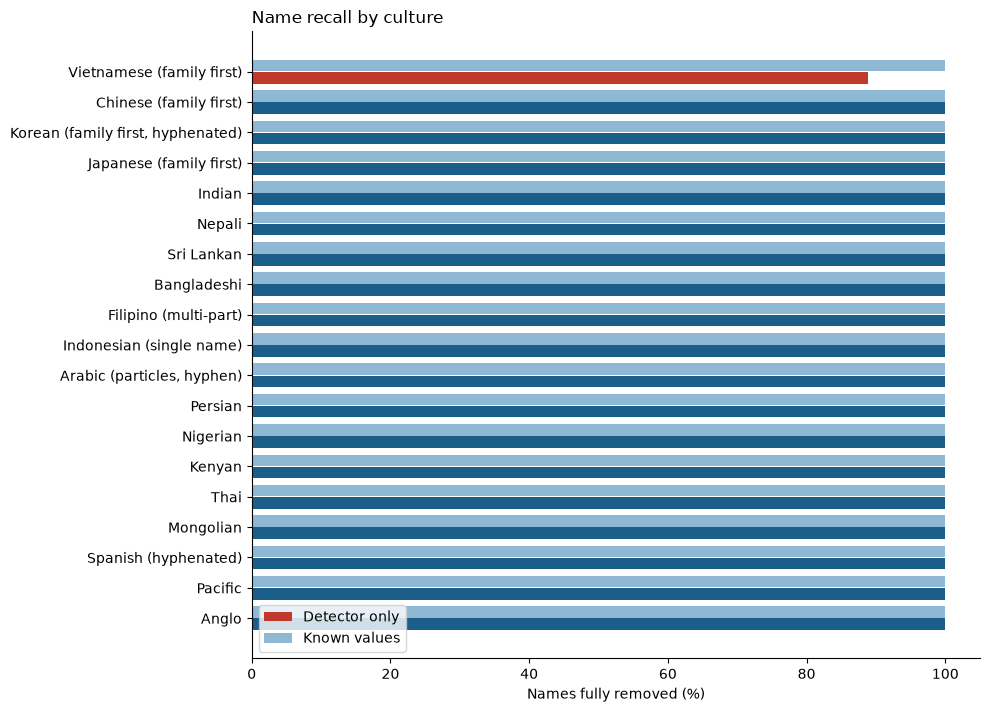

In [7]:
fig, ax = plt.subplots(figsize=(10, max(3, 0.38 * len(cultures))), facecolor="white")
ys = range(len(cultures))
d = [100 * c["det"][0] / max(c["det"][1], 1) for c in cultures]
k = [100 * c["known"][0] / max(c["known"][1], 1) for c in cultures]
ax.barh([y + 0.2 for y in ys], d, height=0.38, label="Detector only", color=[BAR_COLOR if v >= THRESHOLD else WARN_COLOR for v in d])
ax.barh([y - 0.2 for y in ys], k, height=0.38, label="Known values", color="#8fb8d4")
ax.set_yticks(list(ys)); ax.set_yticklabels([c["group"] for c in cultures]); ax.invert_yaxis()
ax.set_xlim(0, 105); ax.set_xlabel("Names fully removed (%)"); ax.set_title("Name recall by culture", loc="left")
ax.spines[["top", "right"]].set_visible(False); ax.legend(loc="lower left")
fig.tight_layout(); fig.savefig(Path(OUT_DIR) / "redaction_name_recall.png", dpi=150)
plt.show()

## Realistic documents: the full pipeline on actual PDF files

The tables above use a labelled text set. This section runs the **same production code** (PDF text extraction, two-pass redaction, leak scan) on a complete 8-file application: real PDF files with their own layouts, headers, tables and metadata, including a Confirmation of Enrolment in the official CoE layout.

**What this is, and what it is not.** The people, numbers and contact details in these PDFs are fictional (each file says so). Nothing here is a real applicant's data, and we deliberately never put real personal data into a repository or a demo. So this shows that redaction survives real document formats and mixed-document consistency. It is **not** a guarantee for real-world applications: a small, single-applicant check like this one cannot back a claim of 100% on real data. Add more folders to `DOC_DIRS` to widen it.

In [8]:
# ---- Settings: realistic-documents check ----
DOC_DIRS = ["../my_tests/application_1"]   # each folder = one applicant's PDFs (01_Application_Responses.pdf = the form)

# What must NOT reach the AI (value -> type). Read off the PDFs by hand, not by the detector.
MUST_REMOVE = {
    "Sita Karki": "PERSON", "Sita": "PERSON", "KARKI": "PERSON",
    "Anita Rai": "REFEREE", "Prakash Thapa": "REFEREE", "Ramesh Gurung": "REFEREE",
    "14 March 2003": "DOB", "14/03/2003": "DOB",
    "sita.karki.sample@gmail.com": "EMAIL", "anita.rai@hit.example.edu.np": "EMAIL", "prakash@kdw.example.com.np": "EMAIL",
    "+977 9841 555 201": "PHONE", "+977 9851 555 077": "PHONE",
    "PA 4821907": "ID", "4821907": "ID", "XK7R2P": "ID", "618-2204871935": "ID",
    "396793": "ID", "HIT-CE-2022-0381": "ID", "DMA-2025-0381": "ID",
    "House 22, Ward 5": "ADDRESS", "linkedin.com/in/sitakarki-sample": "URL",
}
# Terms the grant rules need: removing them hurts the assessment (over-redaction).
MUST_KEEP = ["Charles Darwin University", "Himalayan Institute of Technology", "Master of Data Science",
             "Master of Information Technology", "Darwin", "3.84", "Dean's Merit Award", "22/02/2027", "30/11/2028",
             "Study NT Scholarship Assessment Panel", "National Student Innovation Showcase"]


In [9]:
import sys
root = report.parent.parent                      # repo root
sys.path.insert(0, str(root))
import warnings; warnings.filterwarnings("ignore")
from redaction.eval import leak_of, _contains
from redaction.extract import extract_document
from redaction.pipeline import run_redaction
from seed.load_demo_applicant import read_files, parse_form

real = []   # one row per (applicant, value)
keeps = []
shown = None
for d in DOC_DIRS:
    files = read_files((here / d).resolve())
    form_file = next(f for f in files if f["declared"] == "application responses")
    form = parse_form(form_file["text"])
    docs = [extract_document(f["name"], f["name"], f["data"]) for f in files]
    out = run_redaction(Path(d).name, form, docs)
    original = "\n".join(x.text for x in docs)
    ai_text = "\n".join(out.ai_texts().values())
    for value, ent in MUST_REMOVE.items():
        n_orig = sum(len(re.findall(re.escape(value), x.text, re.I)) for x in docs)
        if n_orig:
            real.append(dict(applicant=Path(d).name, value=value, type=ent, occurrences=n_orig, leak=leak_of(value, ent, ai_text)))
    keeps += [dict(term=t, kept=_contains(ai_text, t)) for t in MUST_KEEP if _contains(original, t)]
    shown = (docs, out)

n_all = sum(r["occurrences"] for r in real); n_leak = sum(1 for r in real if r["leak"])
print(f"Pipeline status: {out.status} | AI status: {out.ai_status} | leak scan findings: {len(out.leak_scan.findings)}")
print(f"Documents processed: {len(shown[0])} PDFs  |  distinct personal values checked: {len(real)}  |  occurrences in the originals: {n_all}")
print(f"Values still readable in what the AI would receive: {n_leak}")
print(f"Needed terms kept: {sum(k['kept'] for k in keeps)}/{len(keeps)}")
for r in real:
    if r["leak"]: print("  LEAK:", r["value"], f"({r['type']})", "->", r["leak"])
for k in keeps:
    if not k["kept"]: print("  OVER-REDACTED:", k["term"])


Pipeline status: ok | AI status: ready | leak scan findings: 0
Documents processed: 8 PDFs  |  distinct personal values checked: 22  |  occurrences in the originals: 74
Values still readable in what the AI would receive: 0
Needed terms kept: 11/11


### Per-value results

In [10]:
try:
    import pandas as pd
    from IPython.display import display
    df = pd.DataFrame(real).assign(result=lambda x: x["leak"].map(lambda v: "LEAKED " + v if v else "removed"))
    display(df.groupby("type").agg(values=("value", "count"), occurrences=("occurrences", "sum"),
                                   leaked=("leak", lambda s: s.notna().sum())).reset_index())
    display(df[["value", "type", "occurrences", "result"]])
except ImportError:
    for r in real: print(r)


{'applicant': 'application_1', 'value': 'Sita Karki', 'type': 'PERSON', 'occurrences': 9, 'leak': None}
{'applicant': 'application_1', 'value': 'Sita', 'type': 'PERSON', 'occurrences': 21, 'leak': None}
{'applicant': 'application_1', 'value': 'KARKI', 'type': 'PERSON', 'occurrences': 15, 'leak': None}
{'applicant': 'application_1', 'value': 'Anita Rai', 'type': 'REFEREE', 'occurrences': 3, 'leak': None}
{'applicant': 'application_1', 'value': 'Prakash Thapa', 'type': 'REFEREE', 'occurrences': 3, 'leak': None}
{'applicant': 'application_1', 'value': 'Ramesh Gurung', 'type': 'REFEREE', 'occurrences': 1, 'leak': None}
{'applicant': 'application_1', 'value': '14 March 2003', 'type': 'DOB', 'occurrences': 1, 'leak': None}
{'applicant': 'application_1', 'value': '14/03/2003', 'type': 'DOB', 'occurrences': 1, 'leak': None}
{'applicant': 'application_1', 'value': 'sita.karki.sample@gmail.com', 'type': 'EMAIL', 'occurrences': 3, 'leak': None}
{'applicant': 'application_1', 'value': 'anita.rai@h

### Before and after, from the PDFs

In [11]:
docs, out = shown
for doc, red in zip(docs, out.documents):
    if doc.file_name.startswith(("02_", "03_", "08_")):
        print("=" * 100); print(doc.file_name)
        a = doc.text.splitlines(); b = red.redacted_text.splitlines()
        changed = [(x, y) for x, y in zip(a, b) if x != y][:6]
        for x, y in changed:
            print("  ORIGINAL :", x[:95]); print("  AI SEES  :", y[:95]); print()


02_CoE Certificate.pdf
  ORIGINAL : Overseas Student Confirmation-of-Enrolment (CoE)
  AI SEES  : Overseas Student Confirmation-of-Enrolment ([PERSON_5])

  ORIGINAL : Telephone: 0889466004, Fax: 0889466059
  AI SEES  : Telephone: [PHONE_2], Fax: [PHONE_3]

  ORIGINAL : Provide rStudent Id:396793
  AI SEES  : Provide rStudent Id:[ID_1]

  ORIGINAL : Family Name: KARKI
  AI SEES  : Family Name: [PERSON_1]

  ORIGINAL : Given Names:Sita
  AI SEES  : Given Names:[PERSON_1]

  ORIGINAL : Date of Birth:14/03/2003
  AI SEES  : Date of Birth:[DOB_1]

03_Flight_Booking_Itinerary.pdf
  ORIGINAL : E-ticket itinerary and receipt | Kathmandu, Nepal | +977 1 555 0142
  AI SEES  : E-ticket itinerary and receipt | [PERSON_3], Nepal | [PHONE_4]

  ORIGINAL : Booking reference (PNR) XK7R2P
  AI SEES  : Booking reference (PNR) [ID_2]

  ORIGINAL : E-ticket number 618-2204871935
  AI SEES  : E-ticket number [ID_3]

  ORIGINAL : Passenger KARKI / SITA MS
  AI SEES  : Passenger [PERSON_1] / [PERSON_1] MS



### Chart

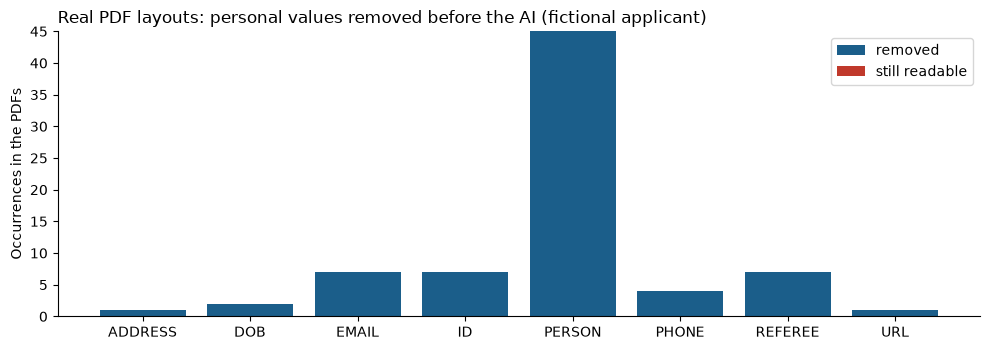

In [12]:
fig, ax = plt.subplots(figsize=(10, 3.6), facecolor="white")
types = sorted({r["type"] for r in real})
tot = [sum(r["occurrences"] for r in real if r["type"] == t) for t in types]
lk = [sum(r["occurrences"] for r in real if r["type"] == t and r["leak"]) for t in types]
ax.bar(types, [a - b for a, b in zip(tot, lk)], color=BAR_COLOR, label="removed")
ax.bar(types, lk, bottom=[a - b for a, b in zip(tot, lk)], color=WARN_COLOR, label="still readable")
ax.set_ylabel("Occurrences in the PDFs"); ax.set_title("Real PDF layouts: personal values removed before the AI (fictional applicant)", loc="left")
ax.spines[["top", "right"]].set_visible(False); ax.legend()
fig.tight_layout(); fig.savefig(Path(OUT_DIR) / "redaction_real_documents.png", dpi=150); plt.show()


### Reading the result

* **Removed** = the value (or any 3+ letter part of a name, or any phone/date reformatting) cannot be found in the text the AI would receive.
* The leak scan is a second, independent check that blocks the AI call if anything slips through; it reports the findings count above.
* **Over-redaction is shown honestly.** The pipeline prefers removing too much to leaking: for example, place names such as the home city can be replaced by a person token. That costs the assessor a little context, not privacy.
* To widen this beyond one applicant: put more folders of PDFs next to `my_tests/application_1`, list them in `DOC_DIRS`, and add each applicant's values to `MUST_REMOVE`.